<a href="https://colab.research.google.com/github/chawlaniharika23/Fraud_Detection_Research/blob/main/notebooks/02_baseline_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 — Baseline Models for Financial Fraud Detection

## Objective
This notebook establishes baseline machine-learning performance for the IEEE-CIS fraud-detection dataset. The results will serve as reference points for evaluating more advanced models in subsequent experiments.

## Models
1. Logistic Regression
2. Random Forest
3. XGBoost

## Evaluation
We will examine precision, recall, F1-score, ROC-AUC, and average precision (PR-AUC), with particular attention to fraud detection under class imbalance.

## Reproducibility
Random seeds will be fixed where applicable, and preprocessing will be fitted on training data only to reduce data leakage.

In [ ]:
import os
import gc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    PrecisionRecallDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")
print("Random seed:", RANDOM_STATE)

Libraries imported successfully.
Random seed: 42


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DATA_DIR = "/content/drive/MyDrive/fraud-detection-research/data"

train_transaction_path = os.path.join(
    DATA_DIR, "train_transaction.csv"
)

train_identity_path = os.path.join(
    DATA_DIR, "train_identity.csv"
)

if not os.path.exists(train_transaction_path):
    raise FileNotFoundError(
        f"Training file not found: {train_transaction_path}. "
        "Update DATA_DIR to your actual dataset location."
    )

train_transaction = pd.read_csv(train_transaction_path)

print("Transaction data shape:", train_transaction.shape)
print("\nFirst five rows:")
display(train_transaction.head())

print("\nTarget distribution:")
display(train_transaction["isFraud"].value_counts().to_frame("Count"))

Transaction data shape: (590540, 394)

First five rows:


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Target distribution:


,Count
isFraud,
0,569877
1,20663


In [ ]:
# Merge identity features when the file is available.
if os.path.exists(train_identity_path):
    train_identity = pd.read_csv(train_identity_path)

    df = train_transaction.merge(
        train_identity,
        on="TransactionID",
        how="left"
    )

    del train_identity
    gc.collect()

    print("Transaction and identity data merged.")
else:
    df = train_transaction.copy()
    print("Identity file not found; using transaction data only.")

TARGET = "isFraud"

# Separate features and target.
y = df[TARGET].astype("int8")
X = df.drop(columns=[TARGET])

# Remove transaction identifier; it is not a predictive feature.
X = X.drop(columns=["TransactionID"], errors="ignore")

# Remove columns that are entirely missing.
all_missing = X.columns[X.isna().all()].tolist()
X = X.drop(columns=all_missing)

# Convert categorical/object columns into numeric category codes.
# Missing values remain NaN for later imputation.
for col in X.select_dtypes(include=["object", "category"]).columns:
    X[col] = X[col].astype("category").cat.codes.replace(-1, np.nan)

# Use a stratified sample for faster initial experiments.
SAMPLE_SIZE = min(100_000, len(X))

if SAMPLE_SIZE < len(X):
    X, _, y, _ = train_test_split(
        X,
        y,
        train_size=SAMPLE_SIZE,
        stratify=y,
        random_state=RANDOM_STATE
    )

X = X.replace([np.inf, -np.inf], np.nan)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nFraud distribution:")
print(y.value_counts())
print("\nFraud percentage:", round(y.mean() * 100, 3), "%")
print("\nRemoved all-missing columns:", len(all_missing))

Transaction and identity data merged.
Feature matrix shape: (100000, 432)
Target shape: (100000,)

Fraud distribution:
isFraud
0    96501
1     3499
Name: count, dtype: int64

Fraud percentage: 3.499 %

Removed all-missing columns: 0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining fraud rate:", round(y_train.mean() * 100, 3), "%")
print("Testing fraud rate:", round(y_test.mean() * 100, 3), "%")

Training features: (80000, 432)
Testing features: (20000, 432)

Training fraud rate: 3.499 %
Testing fraud rate: 3.5 %


In [ ]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=5,
            class_weight="balanced",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

results = []
fitted_models = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    model.fit(X_train, y_train)
    fitted_models[name] = model

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    result = {
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    }

    results.append(result)
    print(f"{name} training complete.")

results_df = pd.DataFrame(results)

print("\nBaseline results:")
display(results_df.round(4))


Training Logistic Regression...
Logistic Regression training complete.

Training Random Forest...
Random Forest training complete.

Baseline results:


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931
1,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081


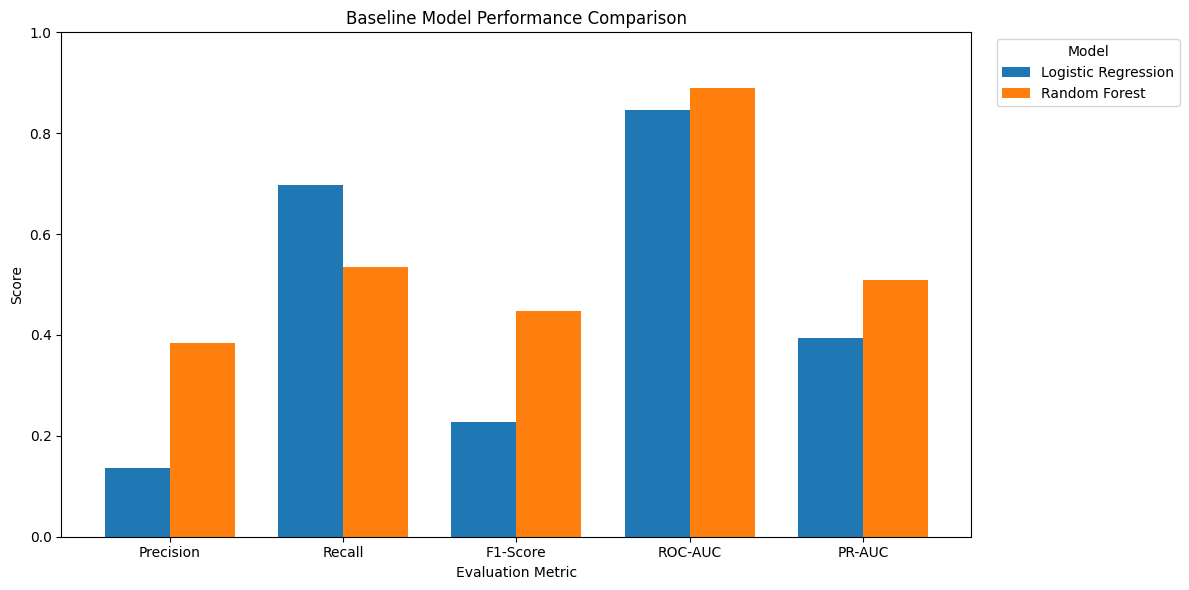

In [ ]:
metrics = ["Precision", "Recall", "F1-Score", "ROC-AUC", "PR-AUC"]

plot_df = results_df.set_index("Model")[metrics]

ax = plot_df.T.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title("Baseline Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation Metric")
ax.set_ylim(0, 1)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

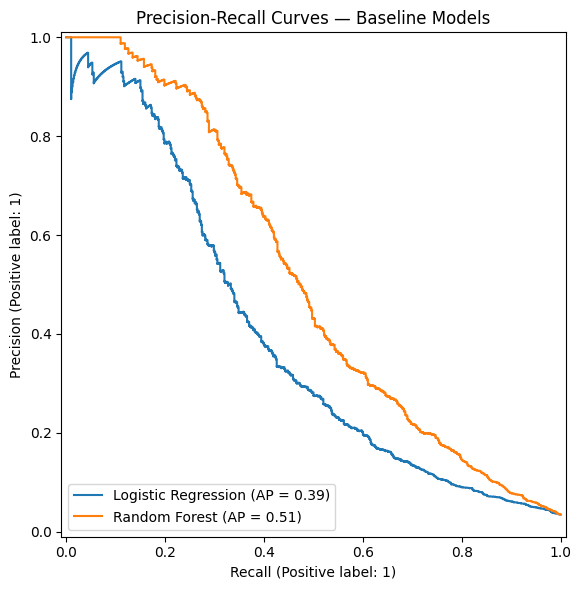

In [ ]:
plt.figure(figsize=(9, 6))

for name, model in fitted_models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    PrecisionRecallDisplay.from_predictions(
        y_test,
        y_prob,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision-Recall Curves — Baseline Models")
plt.tight_layout()
plt.show()

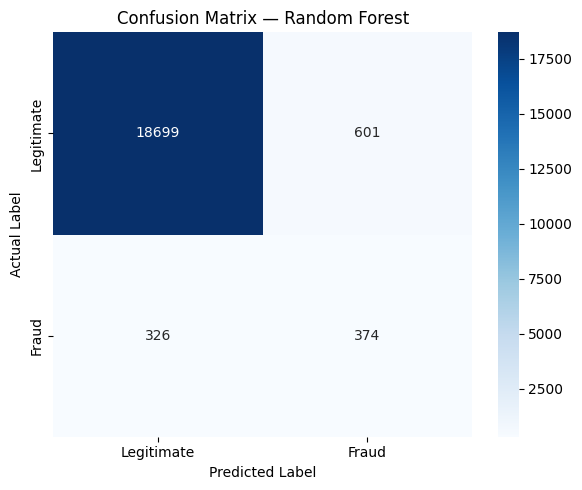

Selected baseline: Random Forest

Classification report:
              precision    recall  f1-score   support

  Legitimate       0.98      0.97      0.98     19300
       Fraud       0.38      0.53      0.45       700

    accuracy                           0.95     20000
   macro avg       0.68      0.75      0.71     20000
weighted avg       0.96      0.95      0.96     20000



In [ ]:
best_model_name = results_df.loc[
    results_df["PR-AUC"].idxmax(), "Model"
]

best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

print("Selected baseline:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

In [ ]:
RESULTS_DIR = os.path.join(
    "/content/drive/MyDrive/fraud-detection-research",
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

results_path = os.path.join(
    RESULTS_DIR,
    "baseline_model_results.csv"
)

results_df.to_csv(results_path, index=False)

print("Results saved to:", results_path)
display(pd.read_csv(results_path).round(4))

Results saved to: /content/drive/MyDrive/fraud-detection-research/results/baseline_model_results.csv


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931
1,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081


In [ ]:
# Final baseline comparison
results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print("BASELINE MODEL RANKING")
display(results_df.round(4))

print("\nBest baseline by PR-AUC:")
print(results_df.iloc[0]["Model"])

# Save a local copy in Colab as well
results_df.to_csv(
    "/content/baseline_model_results.csv",
    index=False
)

print("\nResults saved successfully.")

BASELINE MODEL RANKING


,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Random Forest,0.3836,0.5343,0.4466,0.8901,0.5081
1,Logistic Regression,0.1358,0.6971,0.2273,0.8459,0.3931



Best baseline by PR-AUC:
Random Forest

Results saved successfully.
